### Mutation Combination Effect

#### First check co-occurrance pattern of mutations


In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
df_biotype = pd.read_csv("treeWAS_phen.csv")
df_snps = pd.read_csv("treeWAS_snps_Group_791-814.csv")
df_snps = df_snps.rename(columns={"Unnamed: 0": "Accession"})

df_all = pd.merge(df_biotype, df_snps, on="Accession")
snp_cols = [col for col in df_all.columns if col.startswith("SNP_")]

df_all["biotype"] = df_all["biotype"].astype(int)
for col in snp_cols:
    df_all[col] = df_all[col].astype(int)

df_all

,Accession,biotype,SNP_791,SNP_809,SNP_811,SNP_814
0,PQ416775.1,1,0,0,0,0
1,PX315748.1,1,0,0,1,0
2,PX315749.1,1,1,1,0,1
3,PX315750.1,1,1,1,0,1
4,PX315751.1,1,0,0,0,1
...,...,...,...,...,...,...
119,AB088222.1,1,1,0,0,1
120,FJ917522.1,0,1,1,1,0
121,FJ917535.1,1,1,1,1,0
122,FJ917523.1,1,1,1,1,0


In [3]:
# values count for each SNP
for col in snp_cols:
    print(f"{col} value counts:")
    print(df_all[col].value_counts())
    print()

SNP_791 value counts:
SNP_791
0    85
1    39
Name: count, dtype: int64

SNP_809 value counts:
SNP_809
0    67
1    57
Name: count, dtype: int64

SNP_811 value counts:
SNP_811
0    102
1     22
Name: count, dtype: int64

SNP_814 value counts:
SNP_814
0    93
1    31
Name: count, dtype: int64



In [4]:
summary_rows = []
for col in snp_cols:
    overall_rate = df_all[col].mean()
    fip_rate = df_all.loc[df_all["biotype"] == 1, col].mean()
    fecv_rate = df_all.loc[df_all["biotype"] == 0, col].mean()
    summary_rows.append({
        "SNP": col,
        "overall_positive_rate": overall_rate,
        "biotype_1_positive_rate": fip_rate,
        "biotype_0_positive_rate": fecv_rate,
    })

summary_df = pd.DataFrame(summary_rows).sort_values("overall_positive_rate", ascending=False)
summary_df


,SNP,overall_positive_rate,biotype_1_positive_rate,biotype_0_positive_rate
1,SNP_809,0.459677,0.554054,0.32
0,SNP_791,0.314516,0.418919,0.16
3,SNP_814,0.250000,0.418919,0.00
2,SNP_811,0.177419,0.283784,0.02


#### Vizualize co-occurrance pattern of two mutatoins

- left: number of samples when two mutations are both 1 at the same time
- right: Jaccard index = number of co-occuranace / number of samples at least one is 1
- bottom: number of co-occurrance by biotype


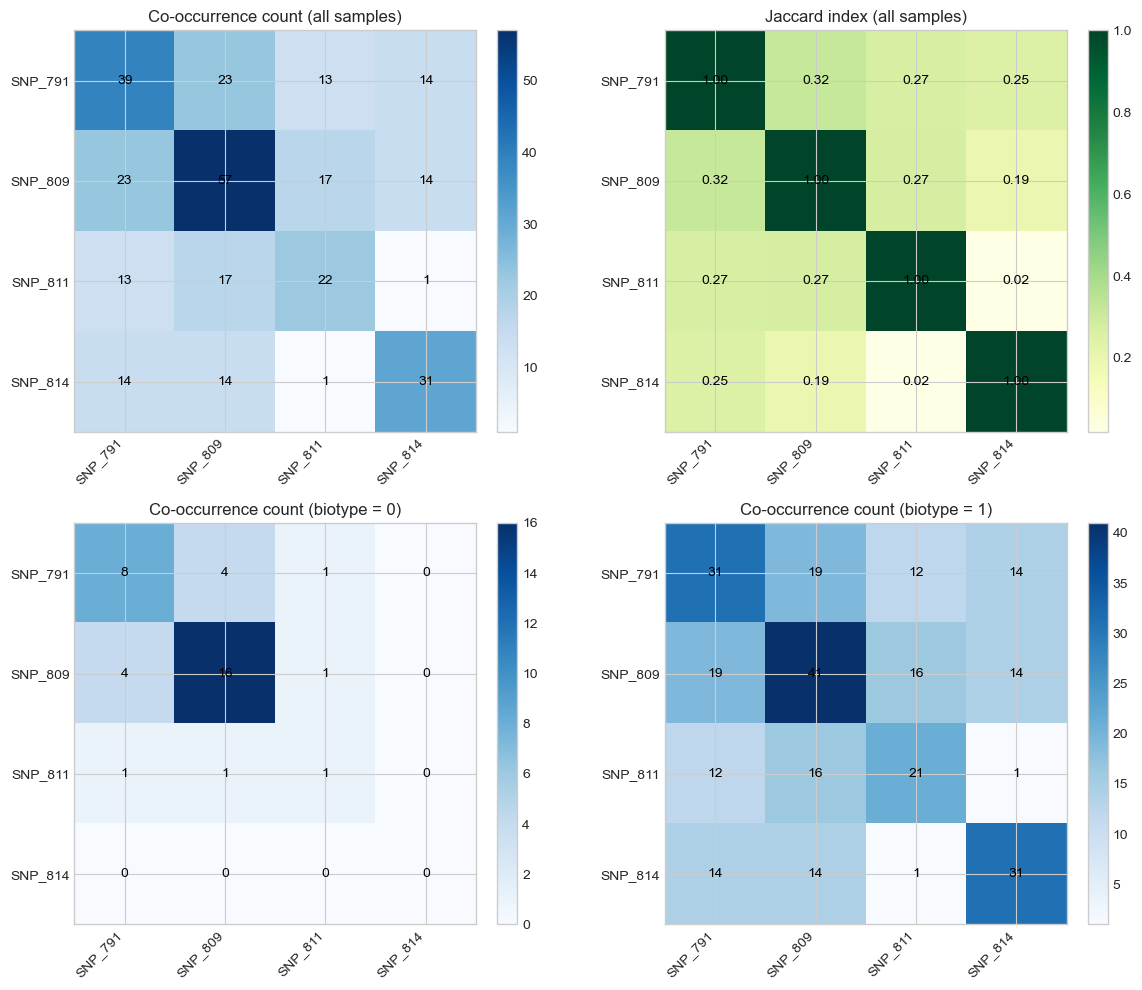

In [5]:
def build_pairwise_matrices(df, feature_cols):
    count_mat = pd.DataFrame(0.0, index=feature_cols, columns=feature_cols)
    jaccard_mat = pd.DataFrame(0.0, index=feature_cols, columns=feature_cols)

    for a in feature_cols:
        xa = df[a].astype(bool)
        count_mat.loc[a, a] = xa.sum()
        jaccard_mat.loc[a, a] = 1.0

    for a, b in itertools.combinations(feature_cols, 2):
        xa = df[a].astype(bool)
        xb = df[b].astype(bool)
        inter = (xa & xb).sum()
        union = (xa | xb).sum()
        jaccard = inter / union if union else np.nan

        count_mat.loc[a, b] = count_mat.loc[b, a] = inter
        jaccard_mat.loc[a, b] = jaccard_mat.loc[b, a] = jaccard

    return count_mat, jaccard_mat


def draw_heatmap(ax, matrix, title, fmt=".0f", cmap="Blues"):
    values = matrix.to_numpy(dtype=float)
    im = ax.imshow(values, cmap=cmap, aspect="equal")
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_yticks(range(len(matrix.index)))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax.set_yticklabels(matrix.index)
    ax.set_title(title)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]
            if np.isnan(value):
                label = "NA"
            else:
                label = format(value, fmt)
            ax.text(j, i, label, ha="center", va="center", color="black", fontsize=10)

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)


count_all, jaccard_all = build_pairwise_matrices(df_all, snp_cols)
count_biotype0, _ = build_pairwise_matrices(df_all[df_all["biotype"] == 0], snp_cols)
count_biotype1, _ = build_pairwise_matrices(df_all[df_all["biotype"] == 1], snp_cols)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
draw_heatmap(axes[0, 0], count_all, "Co-occurrence count (all samples)")
draw_heatmap(axes[0, 1], jaccard_all, "Jaccard index (all samples)", fmt=".2f", cmap="YlGn")
draw_heatmap(axes[1, 0], count_biotype0, "Co-occurrence count (biotype = 0)")
draw_heatmap(axes[1, 1], count_biotype1, "Co-occurrence count (biotype = 1)")
plt.tight_layout()
plt.show()

In [6]:
pair_rows = []
for a, b in itertools.combinations(snp_cols, 2):
    mask_a = df_all[a] == 1
    mask_b = df_all[b] == 1
    n11 = int((mask_a & mask_b).sum())
    n10 = int((mask_a & ~mask_b).sum())
    n01 = int((~mask_a & mask_b).sum())
    n00 = int((~mask_a & ~mask_b).sum())
    biotype_1_rate_when_double_pos = df_all.loc[mask_a & mask_b, "biotype"].mean()
    pair_rows.append({
        "SNP_A": a,
        "SNP_B": b,
        "n11": n11,
        "n10": n10,
        "n01": n01,
        "n00": n00,
        "jaccard": jaccard_all.loc[a, b],
        "biotype_1_rate_when_double_positive": biotype_1_rate_when_double_pos,
    })

pair_summary_df = pd.DataFrame(pair_rows).sort_values(["n11", "jaccard"], ascending=False)
pair_summary_df.reset_index(drop=True, inplace=True)
pair_summary_df

,SNP_A,SNP_B,n11,n10,n01,n00,jaccard,biotype_1_rate_when_double_positive
0,SNP_791,SNP_809,23,16,34,51,0.315068,0.826087
1,SNP_809,SNP_811,17,40,5,62,0.274194,0.941176
2,SNP_791,SNP_814,14,25,17,68,0.250000,1.000000
3,SNP_809,SNP_814,14,43,17,50,0.189189,1.000000
4,SNP_791,SNP_811,13,26,9,76,0.270833,0.923077
5,SNP_811,SNP_814,1,21,30,72,0.019231,1.000000


#### Sample details depending of the combination of mutations

 - Check what combination of SNPs in each sample and how many of these were biotype = 1


In [7]:
combination_summary = (
    df_all.groupby(snp_cols, dropna=False)
    .agg(
        n_samples=("Accession", "size"),
        n_biotype_1=("biotype", "sum"),
        biotype_1_rate=("biotype", "mean"),
    )
    .reset_index()
    .sort_values(["n_samples", "biotype_1_rate"], ascending=[False, False])
)

combination_summary.reset_index(drop=True, inplace=True)
combination_summary

,SNP_791,SNP_809,SNP_811,SNP_814,n_samples,n_biotype_1,biotype_1_rate
0,0,0,0,0,40,10,0.250000
1,0,1,0,0,20,8,0.400000
2,1,1,1,0,13,12,0.923077
3,0,1,0,1,10,10,1.000000
4,1,0,0,1,10,10,1.000000
5,0,0,0,1,6,6,1.000000
6,1,1,0,0,6,3,0.500000
7,1,0,0,0,6,2,0.333333
8,0,0,1,0,4,4,1.000000
9,0,1,1,0,4,4,1.000000


#### Association between SNP combinations and biotype

- First, check each SNP alone with logistic regression
- Next, check each co-occurring pair with Fisher's exact test
- Finally, test whether the pair has an interaction effect after adjusting for the main effects of all SNPs


In [8]:
import warnings

import statsmodels.api as sm
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import PerfectSeparationError


def fit_single_snp_logistic(df, feature, label_col="biotype"):
    tmp = df[[label_col, feature]].dropna().copy()
    y = tmp[label_col].astype(float)
    X = sm.add_constant(tmp[[feature]].astype(float), has_constant="add")

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = sm.GLM(y, X, family=sm.families.Binomial()).fit()

        coef = result.params[feature]
        se = result.bse[feature]
        return {
            "feature": feature,
            "status": "ok",
            "coef": coef,
            "odds_ratio": float(np.exp(coef)),
            "ci_low": float(np.exp(coef - 1.96 * se)),
            "ci_high": float(np.exp(coef + 1.96 * se)),
            "p_value": result.pvalues[feature],
            "n_positive": int(tmp[feature].sum()),
            "n_samples": len(tmp),
        }
    except (PerfectSeparationError, np.linalg.LinAlgError):
        return {
            "feature": feature,
            "status": "model_failed",
            "coef": np.nan,
            "odds_ratio": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "n_positive": int(tmp[feature].sum()),
            "n_samples": len(tmp),
        }


def fisher_for_double_positive(df, feat_a, feat_b, label_col="biotype"):
    double_pos = (df[feat_a] == 1) & (df[feat_b] == 1)
    case = df[label_col] == 1

    n11 = int((double_pos & case).sum())
    n10 = int((double_pos & ~case).sum())
    n01 = int((~double_pos & case).sum())
    n00 = int((~double_pos & ~case).sum())

    odds_ratio, p_value = fisher_exact([[n11, n10], [n01, n00]], alternative="two-sided")
    return {
        "SNP_A": feat_a,
        "SNP_B": feat_b,
        "n_double_positive": int(double_pos.sum()),
        "case_double_positive": n11,
        "control_double_positive": n10,
        "case_other": n01,
        "control_other": n00,
        "double_positive_case_rate": df.loc[double_pos, label_col].mean(),
        "fisher_odds_ratio": odds_ratio,
        "fisher_p_value": p_value,
    }


def fit_pair_interaction_logistic(df, feat_a, feat_b, feature_cols, label_col="biotype"):
    tmp = df[[label_col] + feature_cols].dropna().copy()
    inter_col = f"{feat_a}__x__{feat_b}"
    tmp[inter_col] = tmp[feat_a] * tmp[feat_b]

    if tmp[inter_col].nunique() < 2:
        return {
            "SNP_A": feat_a,
            "SNP_B": feat_b,
            "interaction": inter_col,
            "status": "no_variation",
            "coef_interaction": np.nan,
            "or_interaction": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "n_double_positive": int(tmp[inter_col].sum()),
        }

    y = tmp[label_col].astype(float)
    X = sm.add_constant(tmp[feature_cols + [inter_col]].astype(float), has_constant="add")

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result = sm.GLM(y, X, family=sm.families.Binomial()).fit()

        coef = result.params[inter_col]
        se = result.bse[inter_col]
        return {
            "SNP_A": feat_a,
            "SNP_B": feat_b,
            "interaction": inter_col,
            "status": "ok",
            "coef_interaction": coef,
            "or_interaction": float(np.exp(coef)),
            "ci_low": float(np.exp(coef - 1.96 * se)),
            "ci_high": float(np.exp(coef + 1.96 * se)),
            "p_value": result.pvalues[inter_col],
            "aic": result.aic,
            "n_double_positive": int(tmp[inter_col].sum()),
        }
    except (PerfectSeparationError, np.linalg.LinAlgError):
        return {
            "SNP_A": feat_a,
            "SNP_B": feat_b,
            "interaction": inter_col,
            "status": "model_failed",
            "coef_interaction": np.nan,
            "or_interaction": np.nan,
            "ci_low": np.nan,
            "ci_high": np.nan,
            "p_value": np.nan,
            "aic": np.nan,
            "n_double_positive": int(tmp[inter_col].sum()),
        }


def summarize_four_groups(df, feat_a, feat_b, label_col="biotype"):
    tmp = df[[feat_a, feat_b, label_col]].copy()
    tmp["group"] = (
        feat_a + "_" + tmp[feat_a].astype(str) + "__" + feat_b + "_" + tmp[feat_b].astype(str)
    )
    return (
        tmp.groupby("group", dropna=False)
        .agg(
            n_samples=(label_col, "size"),
            n_biotype_1=(label_col, "sum"),
            biotype_1_rate=(label_col, "mean"),
        )
        .reset_index()
    )

In [9]:
single_snp_results = pd.DataFrame(
    [fit_single_snp_logistic(df_all, feature) for feature in snp_cols]
)

valid_mask = single_snp_results["p_value"].notna()
single_snp_results["p_value_fdr"] = np.nan
if valid_mask.any():
    single_snp_results.loc[valid_mask, "p_value_fdr"] = multipletests(
        single_snp_results.loc[valid_mask, "p_value"],
        method="fdr_bh",
    )[1]

single_snp_results = single_snp_results.sort_values(["p_value_fdr", "odds_ratio"], ascending=[True, False])
single_snp_results

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_96726/3084162939.py:27: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),


,feature,status,coef,odds_ratio,ci_low,ci_high,p_value,n_positive,n_samples,p_value_fdr
2,SNP_811,ok,2.966051,1.941509e+01,2.515992,149.819967,0.004441,22,124,0.008882
0,SNP_791,ok,1.331015,3.784884e+00,1.560573,9.179539,0.003234,39,124,0.008882
1,SNP_809,ok,0.970836,2.640152e+00,1.246540,5.591799,0.011227,57,124,0.014970
3,SNP_814,ok,23.716891,1.995791e+10,0.000000,inf,0.998674,31,124,0.998674


In [10]:
pair_fisher_results = pd.DataFrame(
    [fisher_for_double_positive(df_all, a, b) for a, b in itertools.combinations(snp_cols, 2)]
)

valid_mask = pair_fisher_results["fisher_p_value"].notna()
pair_fisher_results["fisher_p_value_fdr"] = np.nan
if valid_mask.any():
    pair_fisher_results.loc[valid_mask, "fisher_p_value_fdr"] = multipletests(
        pair_fisher_results.loc[valid_mask, "fisher_p_value"],
        method="fdr_bh",
    )[1]

pair_fisher_results = pair_fisher_results.sort_values(
    ["fisher_p_value_fdr", "double_positive_case_rate"],
    ascending=[True, False],
)
pair_fisher_results

,SNP_A,SNP_B,n_double_positive,case_double_positive,control_double_positive,case_other,control_other,double_positive_case_rate,fisher_odds_ratio,fisher_p_value,fisher_p_value_fdr
2,SNP_791,SNP_814,14,14,0,60,50,1.000000,inf,0.000746,0.002237
4,SNP_809,SNP_814,14,14,0,60,50,1.000000,inf,0.000746,0.002237
3,SNP_809,SNP_811,17,16,1,58,49,0.941176,13.517241,0.001235,0.002471
1,SNP_791,SNP_811,13,12,1,62,49,0.923077,9.483871,0.014417,0.020939
0,SNP_791,SNP_809,23,19,4,55,46,0.826087,3.972727,0.017450,0.020939
5,SNP_811,SNP_814,1,1,0,73,50,1.000000,inf,1.000000,1.000000


In [12]:
pair_interaction_results = pd.DataFrame(
    [
        fit_pair_interaction_logistic(df_all, a, b, snp_cols)
        for a, b in itertools.combinations(snp_cols, 2)
    ]
)

valid_mask = (pair_interaction_results["status"] == "ok") & pair_interaction_results["p_value"].notna()
pair_interaction_results["p_value_fdr"] = np.nan
if valid_mask.any():
    pair_interaction_results.loc[valid_mask, "p_value_fdr"] = multipletests(
        pair_interaction_results.loc[valid_mask, "p_value"],
        method="fdr_bh",
    )[1]

pair_interaction_results = pair_interaction_results.sort_values(
    ["p_value_fdr", "or_interaction"],
    ascending=[True, False],
)

pair_interaction_results

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_96726/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_96726/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_96726/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_96726/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),
/var/folders/9v/b3wtpj5n6f30_z6c2cnt7rdr0000gn/T/ipykernel_96726/3084162939.py:107: RuntimeWarning: overflow encountered in exp
  "ci_high": float(np.exp(coef + 1.96 * se)),


,SNP_A,SNP_B,interaction,status,coef_interaction,or_interaction,ci_low,ci_high,p_value,aic,n_double_positive,p_value_fdr
2,SNP_791,SNP_814,SNP_791__x__SNP_814,ok,0.132589,1.141780e+00,0.000000,inf,0.999996,108.523594,14,0.999996
0,SNP_791,SNP_809,SNP_791__x__SNP_809,ok,-0.317631,7.278712e-01,0.057819,9.162957,0.805839,108.463501,23,0.999996
4,SNP_809,SNP_814,SNP_809__x__SNP_814,ok,-0.429314,6.509552e-01,0.000000,inf,0.999988,108.523594,14,0.999996
5,SNP_811,SNP_814,SNP_811__x__SNP_814,ok,-3.095031,4.527359e-02,0.000000,inf,0.999969,108.523594,1,0.999996
3,SNP_809,SNP_811,SNP_809__x__SNP_811,ok,-21.176435,6.356105e-10,0.000000,inf,0.999446,107.650872,17,0.999996
1,SNP_791,SNP_811,SNP_791__x__SNP_811,ok,-21.595102,4.181831e-10,0.000000,inf,0.999289,106.914138,13,0.999996
